# 04 - Análisis de errores

Un MAE promedio esconde dónde falla el modelo. Miramos errores por fecha, por régimen de mercado
(calma vs crisis) y por tipo de par (mismo sector vs distinto).

In [1]:
import sys
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

RAIZ = Path.cwd().parent          # el notebook corre desde notebooks/
sys.path.append(str(RAIZ / "backend"))  # para importar app.dataset y app.modelo
DATA = RAIZ / "data"

plt.rcParams["figure.figsize"] = (8, 4)

In [2]:
from app.modelo import FEATURES, TARGET, ajustar, dividir_temporal, metricas, predecir_baseline

dataset = pd.read_csv(DATA / "dataset_pares.csv", parse_dates=["fecha_corte"])
train, test = dividir_temporal(dataset)

modelo, params, _ = ajustar("regresion_lineal", train)
test = test.assign(pred_modelo=modelo.predict(test[FEATURES]), pred_base=predecir_baseline(test))
test["err_modelo"] = (test[TARGET] - test["pred_modelo"]).abs()
test["err_base"] = (test[TARGET] - test["pred_base"]).abs()
print("modelo usado: regresion_lineal (se puede cambiar por 'knn' o 'arbol')")

modelo usado: regresion_lineal (se puede cambiar por 'knn' o 'arbol')


## 1. Predicho vs real y residuos

Si el modelo fuera perfecto, los puntos estarían sobre la diagonal roja. Los residuos
(`real - predicho`) deberían estar centrados en 0; una media distinta de 0 indica **sesgo**.

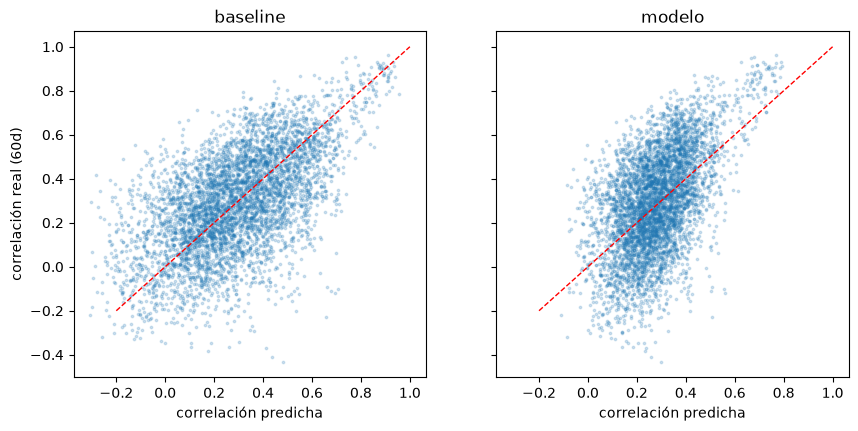

residuo medio baseline: 0.0036
residuo medio modelo:   0.0117


In [3]:
muestra = test.sample(5000, random_state=0)
fig, ejes = plt.subplots(1, 2, figsize=(10, 4.5), sharex=True, sharey=True)
for eje, col, titulo in zip(ejes, ["pred_base", "pred_modelo"], ["baseline", "modelo"]):
    eje.scatter(muestra[col], muestra[TARGET], s=3, alpha=0.2)
    eje.plot([-0.2, 1], [-0.2, 1], "r--", lw=1)
    eje.set_title(titulo); eje.set_xlabel("correlación predicha")
ejes[0].set_ylabel("correlación real (60d)")
plt.show()

print("residuo medio baseline:", round((test[TARGET] - test["pred_base"]).mean(), 4))
print("residuo medio modelo:  ", round((test[TARGET] - test["pred_modelo"]).mean(), 4))

## 2. Error a lo largo del tiempo

¿El error es parejo o hay fechas particularmente malas?

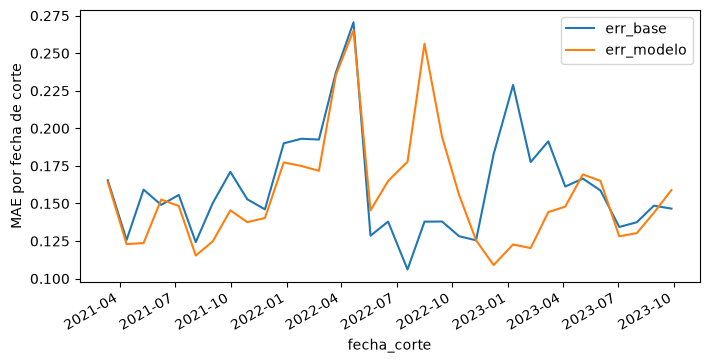

In [4]:
test.groupby("fecha_corte")[["err_base", "err_modelo"]].mean().plot()
plt.ylabel("MAE por fecha de corte")
plt.show()

## 3. Calma vs crisis

Definimos *crisis* como `volatilidad_mercado` por encima del percentil 75 **de train** (el umbral sale
de train para no mirar test). En crisis las acciones tienden a moverse todas juntas, y eso es difícil de anticipar.

In [5]:
umbral = train["volatilidad_mercado"].quantile(0.75)
test["regimen"] = np.where(test["volatilidad_mercado"] > umbral, "crisis", "calma")
test["sector"] = np.where(test["mismo_sector"] == 1, "mismo sector", "distinto sector")

for col in ["regimen", "sector"]:
    print(f"--- por {col} ---")
    print(test.groupby(col)[["err_base", "err_modelo"]].agg(["mean", "count"]).round(4).iloc[:, [0, 2, 1]])

--- por regimen ---
        err_base err_modelo err_base
            mean       mean    count
regimen                             
calma     0.1564     0.1471     8700
crisis    0.1685     0.1705     5655
--- por sector ---
                err_base err_modelo err_base
                    mean       mean    count
sector                                      
distinto sector   0.1628     0.1573    13431
mismo sector      0.1383     0.1420      924


In [6]:
filas = {}
for col in ["regimen", "sector"]:
    for grupo, d in test.groupby(col):
        filas[grupo] = {"n": len(d), "MAE base": d["err_base"].mean(), "MAE modelo": d["err_modelo"].mean(),
                        "corr real media": d[TARGET].mean(), "corr predicha media": d["pred_modelo"].mean()}
pd.DataFrame(filas).T.round(3)

,n,MAE base,MAE modelo,corr real media,corr predicha media
calma,8700.0,0.156,0.147,0.227,0.274
crisis,5655.0,0.169,0.171,0.384,0.282
distinto sector,13431.0,0.163,0.157,0.274,0.262
mismo sector,924.0,0.138,0.142,0.515,0.499


## 4. Lectura de resultados (para el informe)

- **Calma:** el modelo le gana al baseline (MAE 0.147 vs 0.156). **Crisis:** no (0.171 vs 0.169), es apenas peor.
  La mejora promedio viene toda de los períodos tranquilos.
- **Subestima la crisis:** en crisis la correlación real media es ~0.38 y la predicha ~0.28. Cuando el mercado se
  mueve en bloque las acciones se correlacionan más de lo que el modelo anticipa, porque todas las features miran
  el pasado y ningún dato puede adelantar un shock que todavía no ocurrió.
- **Mismo sector vs distinto:** son pocos pares de mismo sector (~900 de ~14.000), y ahí el modelo tampoco mejora
  al baseline. La mejora está en los pares de distinto sector.
- **Consecuencia para el grafo:** el umbral θ aplicado a la correlación predicha en una crisis deja pasar menos
  aristas de las que habría con la correlación real, así que las canastas pueden quedar más correlacionadas de lo esperado.

Estos números son de la regresión lineal; con `knn` o `arbol` en la celda de entrenamiento hay que volver a mirarlos.